Part 1

In [8]:
%pip install pandas matplotlib seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [10]:
data_path = Path("../data/penguins.csv")
penguins = pd.read_csv(data_path)
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [11]:
print(penguins.shape)
print(penguins.dtypes)
print(penguins.info())
print(penguins.isna().sum())

(344, 8)
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB
None
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_leng

Part 2

In [12]:
import sys
sys.path.append("../src")

from cleaning import clean_data, filter_species, summarize_species

In [13]:
penguins_clean = clean_data(penguins)
penguins_clean.shape

(342, 8)

The original dataset contained 344 observations and 8 variables. After removing rows with missing measurements the cleaned dataset now contains 342 observations and 8 variables. 

In [16]:
Chinstrap = filter_species(penguins_clean, "Chinstrap")
Chinstrap.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
276,Chinstrap,Dream,46.5,17.9,192.0,3500.0,female,2007
277,Chinstrap,Dream,50.0,19.5,196.0,3900.0,male,2007
278,Chinstrap,Dream,51.3,19.2,193.0,3650.0,male,2007
279,Chinstrap,Dream,45.4,18.7,188.0,3525.0,female,2007
280,Chinstrap,Dream,52.7,19.8,197.0,3725.0,male,2007


In [15]:
summarize_species(penguins_clean)

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64

Part 3

Does avergae body mass differ between penguin species?

In [17]:
penguins_clean.groupby("species")["body_mass_g"].mean()

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64

The average body mass does differ between penguin species. Gentoo penguins have the highest average body mass at 5,076.02 g, while Adelie and Chinstrap penguins have similar averages of 3,700.66 g and 3,733.09 g. This shows that there is a different in avergae body mass across the penguin species espically with Gentoo compared to Chinstrap and Adelie

Does the distribution of penguin species differ across islands?

In [23]:
penguins_clean.groupby(["island", "species"]).size()

island     species  
Biscoe     Adelie        44
           Gentoo       123
Dream      Adelie        56
           Chinstrap     68
Torgersen  Adelie        51
dtype: int64

The distribution of penguin species does differ across the three islands. Adelie penguins are found on all three islands, while Chinstrap penguins are only found on Dream Island and Gentoo penguins are only found on Biscoe Island. Torgersen Island only had Adelie penguins and Biscoe Island had the most penguins in the dataset with 167 penguins, followed by Dream Island with 124 and Torgersen Island with 51. This shows that the penguin species are not evenly distributed across the sampled islands.

Part 4

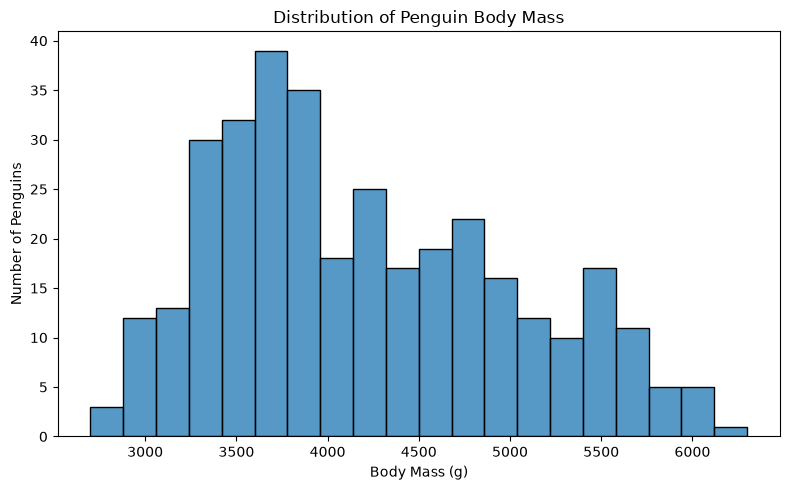

In [28]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=penguins_clean,
    x="body_mass_g",
    bins=20
)

plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (g)")
plt.ylabel("Number of Penguins")

plt.tight_layout()
plt.savefig("../figures/body_mass_histogram.png", dpi=300)
plt.show()

Fig 1. Distribution of body mass among penguins. Body mass varies across the penguins, with some individuals weighing considerably more than others.

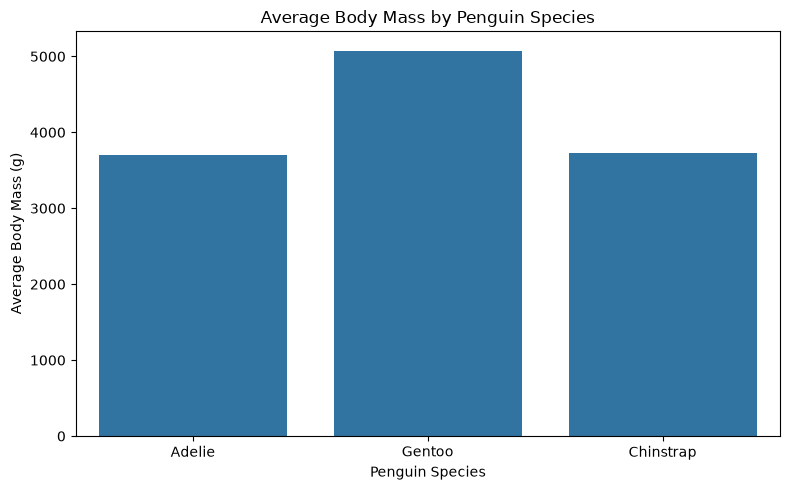

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=penguins_clean,
    x="species",
    y="body_mass_g",
    errorbar=None
)

plt.title("Average Body Mass by Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Average Body Mass (g)")

plt.tight_layout()
plt.savefig("../figures/body_mass_by_species.png", dpi=300)
plt.show()

Fig 2. Gentoo penguins have the highest average body mass (5,076.02 g), while Adelie (3,700.66 g) and Chinstrap (3,733.09 g) penguins have similar averages.

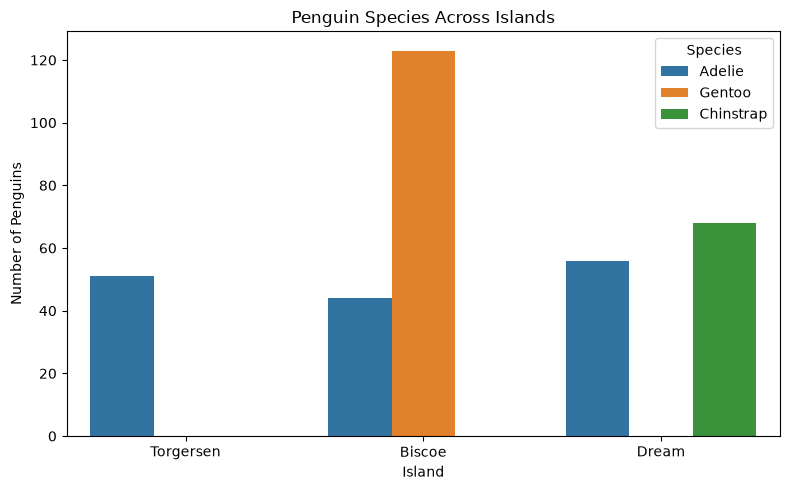

In [32]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=penguins_clean,
    x="island",
    hue="species"
)

plt.title("Penguin Species Across Islands")
plt.xlabel("Island")
plt.ylabel("Number of Penguins")
plt.legend(title="Species")

plt.tight_layout()
plt.savefig("../figures/species_by_island.png", dpi=300)
plt.show()

Fig 3. Adelie penguins are found on all three islands, while Chinstrap penguins are only found on Dream Island and Gentoo penguins are only found on Biscoe Island.

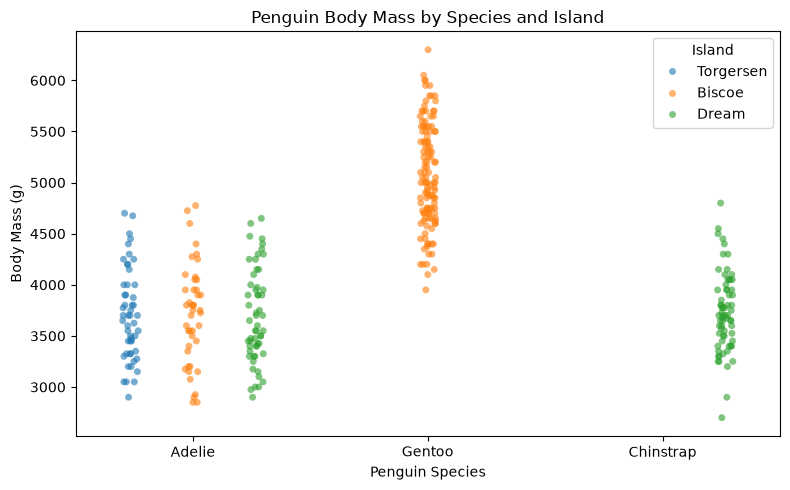

In [35]:
plt.figure(figsize=(8, 5))

sns.stripplot(
    data=penguins_clean,
    x="species",
    y="body_mass_g",
    hue="island",
    dodge=True,
    jitter=True,
    alpha=0.6
)

plt.title("Penguin Body Mass by Species and Island")
plt.xlabel("Penguin Species")
plt.ylabel("Body Mass (g)")
plt.legend(title="Island")

plt.tight_layout()
plt.savefig("../figures/body_mass_species_island.png", dpi=300)
plt.show()

Fig 4. Gentoo penguins generally have higher body masses than Adelie and Chinstrap penguins. Adelie penguins are found across all three islands, while Gentoo and Chinstrap penguins are only recorded on Biscoe and Dream Islands. This suggests that body mass patterns differ by species with species distribution also varying by island.